In [1]:
from mirpredictor import miRPredictor
from auxiliary import *
import scanpy as sc
import pandas as pd
from pathlib import Path
import os

predictor = miRPredictor(device="cuda")

In [6]:
# cervix and melanoma failed

In [21]:
root = Path.cwd() / 'data' / 'part_1'
current_dirs = os.listdir(root)[2:3]

current_dirs

['cervix']

In [23]:
for type in current_dirs:
    current_path = root / type / f'{type}_integrated_adata.h5ad'

    adata = sc.read_h5ad(current_path)

    adata = predictor.predict(adata)
    adata.write(current_path)

    de = predictor.differential_expression(
        adata,
        groupby="CellType",       
        method="wilcoxon",        
        reference=None,            
        mirnas=None,              
        min_cells=3,
        adjust="fdr_bh",
    )
    de.to_csv(root / type / f'{type}_de.csv')

Configuration: 35650 cells, 22971 genes, 159 eligible miRNAs
Predicting 158/159 miRNAs; 1/159 not be predicted due to insufficient features in the current dataset


Predicting miRNAs:   0%|          | 0/158 [00:00<?, ?mir/s]

RuntimeError: NVML_SUCCESS == DriverAPI::get()->nvmlInit_v2_() INTERNAL ASSERT FAILED at "/pytorch/c10/cuda/CUDACachingAllocator.cpp":983, please report a bug to PyTorch. 

In [19]:
adata = sc.read_h5ad('/home/amismailov/mirna-repo/ml_pipeline/data/part_1/cervix/cervix_integrated_adata.h5ad')

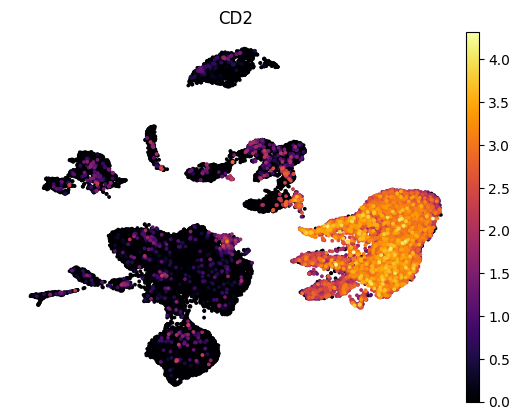

In [20]:
sc.pl.umap(adata, color=['CD2'], legend_loc="on data", size=30, alpha=1, frameon=False, cmap='inferno')